## 3. Анализ данных и выбор спецификации модели

**Входы**

- Данные и постановка задачи

**Выходы**

- Спецификация будущей модели и варианты, которые будем сравнивать при обучении
- Таблица выводов с накопленными знаниями о данных и принятыми решениями
- Подготовленные для дальнейшей работы данные и выборки train, validation и test

**Что делаем**

Основная задача — провести EDA, разобраться в данных и на этой основе выбрать спецификацию будущей модели

**Спецификация модели** — описание того, как она будет устроена: какие признаки подаём на вход, как их готовим, какое семейство зависимостей рассматриваем и какие настройки будем сравнивать. Например, можно допустить линейную зависимость или более сложные связи на основе деревьев

Здесь обосновываем устройство модели и варианты для сравнения. Обученные экземпляры получим на этапе обучения, когда алгоритмы подберут параметры по данным

### Вспомогательные шаги

**Разбиение данных** само по себе можно оформить отдельным этапом после анализа. Здесь делаем его раньше — перед детальным изучением связей, чтобы дальнейший анализ и выбор решений не опирались на validation и test. После разбиения такие проверки выполняем только на train

Первый общий обзор и исправление явных ошибок в нашем порядке работы идут до разбиения. Это ограничение учитываем при обсуждении итоговой оценки

**Часть решений по обработке применяем сразу**. Например, удаляем полные повторы и заменяем недопустимые значения пропусками. Так последующий анализ становится проще. Анализируем данные, принимаем решение, преобразуем их и снова смотрим на результат

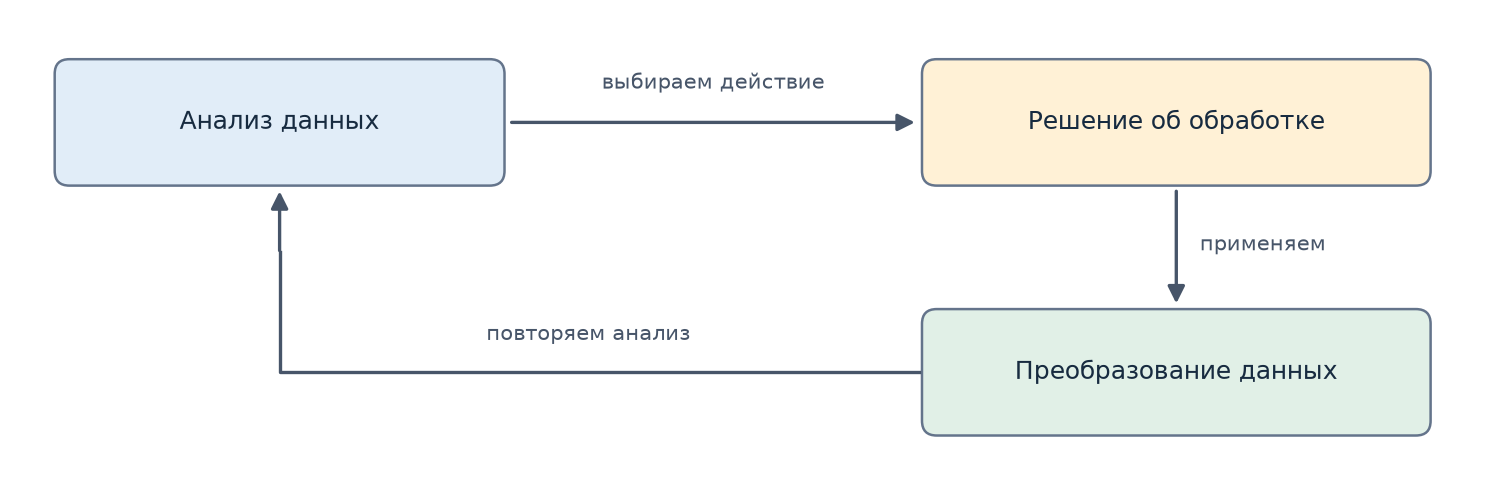

Финальную предобработку под выбранную спецификацию выполняем на этапе 4

### Таблица выводов

По ходу анализа растут наши знания о датасете: появляются наблюдения, предположения и решения. Собираем их в **таблицу выводов**, чтобы не терять контекст внутри этого этапа и передать его на следующий

Таблица — выбранный нами способ организации этой информации

##### Техническая заметка: как ведём таблицу

- Храним её в коде как `conclusions` — таблицу Pandas DataFrame со столбцами «Выводы», «Решения» и «Метка»
- В начале этапа таблица пустая. После подэтапа небольшой скрипт добавляет новые записи или уточняет прежние
- У каждой записи есть постоянный id — имя, по которому находим её при обновлении. Это позволяет заменять вывод или решение без накопления одинаковых актуальных строк
- Новые строки помечаем `new` и показываем зелёным со знаком «+». Удаляемые помечаем `removed` и один раз показываем красным со знаком «−», затем убираем
- На сводных шагах выводим всю таблицу, а после отдельных проверок можем показать только новые строки. К следующему этапу передаём её актуальное содержимое

In [ ]:
# dev-only: подготовка рабочей папки для интерактивного запуска
from pathlib import Path as _NotebookPath
import os as _notebook_os
_notebook_root = next(
    path for path in (_NotebookPath.cwd(), *_NotebookPath.cwd().parents)
    if (path / 'config/build/project.json').is_file()
)
_notebook_os.chdir(_notebook_root)


In [ ]:
# dev-only: загрузчик Python-кода; в сборке заменяется содержимым файла
exec(compile(__import__('pathlib').Path('src/notebooks/03_analysis/_code/findings.py').read_text(encoding='utf-8'), 'src/notebooks/03_analysis/_code/findings.py', 'exec'), globals())


In [ ]:
conclusions = empty_findings()

In [ ]:
# dev-only: загрузчик подэтапа; в сборке заменяется его содержимым

def _include_notebook(_path):
    _document = __import__('json').loads(__import__('pathlib').Path(_path).read_text(encoding='utf-8'))
    for _cell in _document['cells']:
        _source = ''.join(_cell['source'])
        if _cell['cell_type'] == 'markdown':
            for _name, _types in _cell.get('attachments', {}).items():
                for _mime, _data in _types.items():
                    _source = _source.replace('attachment:' + _name, 'data:' + _mime + ';base64,' + _data)
            _display = __import__('IPython.display', fromlist=['Markdown', 'display'])
            _display.display(_display.Markdown(_source))
        elif _cell['cell_type'] == 'code':
            exec(compile(_source, _path, 'exec'), globals())

_include_notebook('src/notebooks/03_analysis/01_basic_eda/index.ipynb')


In [ ]:
# dev-only: загрузчик подэтапа; в сборке заменяется его содержимым

def _include_notebook(_path):
    _document = __import__('json').loads(__import__('pathlib').Path(_path).read_text(encoding='utf-8'))
    for _cell in _document['cells']:
        _source = ''.join(_cell['source'])
        if _cell['cell_type'] == 'markdown':
            for _name, _types in _cell.get('attachments', {}).items():
                for _mime, _data in _types.items():
                    _source = _source.replace('attachment:' + _name, 'data:' + _mime + ';base64,' + _data)
            _display = __import__('IPython.display', fromlist=['Markdown', 'display'])
            _display.display(_display.Markdown(_source))
        elif _cell['cell_type'] == 'code':
            exec(compile(_source, _path, 'exec'), globals())

_include_notebook('src/notebooks/03_analysis/02_split.ipynb')


In [ ]:
# dev-only: загрузчик подэтапа; в сборке заменяется его содержимым

def _include_notebook(_path):
    _document = __import__('json').loads(__import__('pathlib').Path(_path).read_text(encoding='utf-8'))
    for _cell in _document['cells']:
        _source = ''.join(_cell['source'])
        if _cell['cell_type'] == 'markdown':
            for _name, _types in _cell.get('attachments', {}).items():
                for _mime, _data in _types.items():
                    _source = _source.replace('attachment:' + _name, 'data:' + _mime + ';base64,' + _data)
            _display = __import__('IPython.display', fromlist=['Markdown', 'display'])
            _display.display(_display.Markdown(_source))
        elif _cell['cell_type'] == 'code':
            exec(compile(_source, _path, 'exec'), globals())

_include_notebook('src/notebooks/03_analysis/03_correlations/index.ipynb')


In [ ]:
# dev-only: загрузчик подэтапа; в сборке заменяется его содержимым

def _include_notebook(_path):
    _document = __import__('json').loads(__import__('pathlib').Path(_path).read_text(encoding='utf-8'))
    for _cell in _document['cells']:
        _source = ''.join(_cell['source'])
        if _cell['cell_type'] == 'markdown':
            for _name, _types in _cell.get('attachments', {}).items():
                for _mime, _data in _types.items():
                    _source = _source.replace('attachment:' + _name, 'data:' + _mime + ';base64,' + _data)
            _display = __import__('IPython.display', fromlist=['Markdown', 'display'])
            _display.display(_display.Markdown(_source))
        elif _cell['cell_type'] == 'code':
            exec(compile(_source, _path, 'exec'), globals())

_include_notebook('src/notebooks/03_analysis/04_model_choice.ipynb')
